Laboratorio 2: Limpieza y transformación de datos

In [1]:
#Importación de librerías y carga de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Cargar los datasets originales
ventas_original = pd.read_csv('ventas_productos.csv')
empleados_original = pd.read_csv('empleados_rrhh.csv')

# Crear copias de trabajo
df_ventas = ventas_original.copy()
df_empleados = empleados_original.copy()

print("Ventas:", df_ventas.shape)
print("Empleados:", df_empleados.shape)


Ventas: (1530, 7)
Empleados: (600, 10)


Diagnóstico inicial de los datasets

In [3]:
# Primeros registros de ventas
df_ventas.head()

,id_venta,producto,cantidad,precio_unitario,fecha_venta,vendedor,region
0,1,PROD-0076,41.0,248.47,2023-12-31,Diego Castro,SUR
1,2,PROD-0073,20.0,1102.81,2023-02-09,CARLOS RUIZ,Sur
2,3,PROD-0160,41.0,1091.88,2023-08-12,Ana López,Sur
3,4,PROD-0152,34.0,640.48,2023-06-01,Carlos Ruiz,Centro
4,5,PROD-0007,28.0,1387.55,2023-05-20,CARLOS RUIZ,SUR


In [4]:
# Primeros registros de empleados
df_empleados.head()

,id_empleado,departamento,cargo,salario_mensual,antiguedad_anos,edad,satisfaccion_laboral,horas_extra_mes,ausencias_mes,renuncio
0,1,Operaciones,Especialista,1591.98,2.9,25.0,4.7,4.0,2,0
1,2,Marketing,Analista,1246.42,0.1,22.0,5.4,9.0,3,0
2,3,Marketing,Analista,1202.97,0.2,28.0,8.8,8.0,1,0
3,4,Recursos Humanos,Especialista,1665.51,1.9,31.0,8.3,7.0,3,0
4,5,Sistemas,Coordinador,2727.92,9.5,31.0,7.0,12.0,4,0


In [5]:
# Información del dataset de ventas
df_ventas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1530 entries, 0 to 1529
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_venta         1530 non-null   int64  
 1   producto         1483 non-null   object 
 2   cantidad         1501 non-null   float64
 3   precio_unitario  1494 non-null   float64
 4   fecha_venta      1530 non-null   object 
 5   vendedor         1489 non-null   object 
 6   region           1504 non-null   object 
dtypes: float64(2), int64(1), object(4)
memory usage: 83.8+ KB


In [6]:
# Información del dataset de empleados
df_empleados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_empleado           600 non-null    int64  
 1   departamento          600 non-null    object 
 2   cargo                 600 non-null    object 
 3   salario_mensual       572 non-null    float64
 4   antiguedad_anos       600 non-null    float64
 5   edad                  580 non-null    float64
 6   satisfaccion_laboral  568 non-null    float64
 7   horas_extra_mes       600 non-null    float64
 8   ausencias_mes         600 non-null    int64  
 9   renuncio              600 non-null    int64  
dtypes: float64(5), int64(3), object(2)
memory usage: 47.0+ KB


### Interpretación inicial de los datasets

El dataset de ventas contiene 1530 registros y 7 columnas,
mientras que el dataset de empleados contiene 600 registros
y 10 columnas.

En el dataset de ventas se identificaron inconsistencias
en el uso de mayúsculas y minúsculas en las columnas
vendedor y region. Además, la columna fecha_venta se
encuentra almacenada como texto, por lo que será necesario
convertirla a un formato de fecha.

En el dataset de empleados se identificaron valores
faltantes en las columnas salario_mensual, edad y
satisfaccion_laboral.

Se conservaron los datasets originales y se crearon copias
de trabajo para garantizar la trazabilidad de los datos
durante el proceso de limpieza y transformación.

In [7]:
# Estadísticos descriptivos de ventas
df_ventas.describe()

,id_venta,cantidad,precio_unitario
count,1530.000000,1501.000000,1494.000000
mean,752.028758,25.273817,764.507804
std,434.823509,14.334259,429.366436
min,1.000000,-9.000000,-95.568591
25%,375.250000,13.000000,405.902500
50%,751.500000,26.000000,777.150000
75%,1128.750000,38.000000,1123.997500
max,1500.000000,49.000000,1498.420000


In [8]:
# Estadísticos descriptivos de empleados
df_empleados.describe()

,id_empleado,salario_mensual,antiguedad_anos,edad,satisfaccion_laboral,horas_extra_mes,ausencias_mes,renuncio
count,600.000000,572.000000,600.000000,580.000000,568.000000,600.000000,600.000000,600.000000
mean,300.500000,2170.379458,4.023167,31.100000,5.263028,9.573333,2.086667,0.178333
std,173.349358,1268.189304,4.186677,7.172462,2.089144,6.747382,1.446597,0.383112
min,1.000000,1020.480000,0.000000,22.000000,1.000000,0.000000,0.000000,0.000000
25%,150.750000,1354.315000,1.200000,26.000000,3.800000,5.000000,1.000000,0.000000
50%,300.500000,1837.940000,2.800000,30.000000,5.300000,8.000000,2.000000,0.000000
75%,450.250000,2458.682500,5.425000,34.000000,6.600000,12.000000,3.000000,0.000000
max,600.000000,9521.860000,25.000000,65.000000,10.000000,43.000000,7.000000,1.000000


In [9]:
# Variables categóricas de ventas
df_ventas.describe(include='object')

,producto,fecha_venta,vendedor,region
count,1483,1530,1489,1504
unique,200,354,9,9
top,PROD-0067,2023-07-19,Diego Castro,Centro
freq,15,11,176,191


In [10]:
# Variables categóricas de empleados
df_empleados.describe(include='object')

,departamento,cargo
count,600,600
unique,6,5
top,Recursos Humanos,Analista
freq,110,210


### Interpretación de los estadísticos descriptivos

En el dataset de ventas se identificaron valores negativos
en las columnas cantidad y precio_unitario, los cuales
requieren una revisión antes de realizar la imputación.

También se identificaron nueve categorías en la columna
region, aunque la empresa opera únicamente en cinco
regiones, lo que evidencia inconsistencias de texto.

En el dataset de empleados, la diferencia entre la media
y la mediana del salario mensual, junto con su valor
máximo, sugiere la presencia de valores atípicos y una
posible asimetría hacia la derecha.

In [11]:
# Nulos por columna en ventas
nulos_ventas = pd.concat([
    df_ventas.isna().sum(),
    (df_ventas.isna().mean()*100).round(2)
], axis=1)

nulos_ventas.columns = ['n_nulos', 'porcentaje']

nulos_ventas.sort_values('n_nulos', ascending=False)

,n_nulos,porcentaje
producto,47,3.07
vendedor,41,2.68
precio_unitario,36,2.35
cantidad,29,1.90
region,26,1.70
id_venta,0,0.00
fecha_venta,0,0.00


In [12]:
# Nulos por columna en empleados
nulos_empleados = pd.concat([
    df_empleados.isna().sum(),
    (df_empleados.isna().mean()*100).round(2)
], axis=1)

nulos_empleados.columns = ['n_nulos', 'porcentaje']

nulos_empleados.sort_values('n_nulos', ascending=False)

,n_nulos,porcentaje
satisfaccion_laboral,32,5.33
salario_mensual,28,4.67
edad,20,3.33
id_empleado,0,0.00
departamento,0,0.00
cargo,0,0.00
antiguedad_anos,0,0.00
horas_extra_mes,0,0.00
ausencias_mes,0,0.00
renuncio,0,0.00


### Interpretación de los valores faltantes

En el dataset de ventas se identificaron 179 valores
faltantes, distribuidos en cinco columnas. La columna
producto presenta la mayor cantidad de nulos, con
47 registros afectados.

En el dataset de empleados se identificaron 80 valores
faltantes, distribuidos en tres columnas. La columna
satisfaccion_laboral presenta la mayor cantidad de nulos,
con 32 registros, equivalentes al 5.33 %.

Se propone utilizar estrategias de imputación diferenciadas
según el tipo de variable, con el propósito de conservar
la mayor cantidad de información posible y evitar la
eliminación innecesaria de registros.

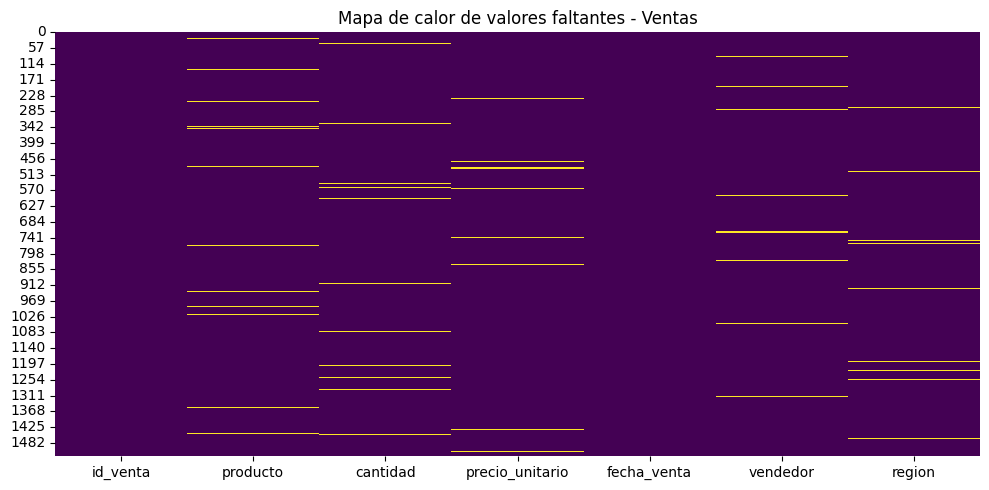

In [13]:
# Mapa de calor de valores faltantes en ventas
plt.figure(figsize=(10, 5))
sns.heatmap(df_ventas.isna(), cbar=False, cmap='viridis')
plt.title('Mapa de calor de valores faltantes - Ventas')
plt.tight_layout()
plt.show()

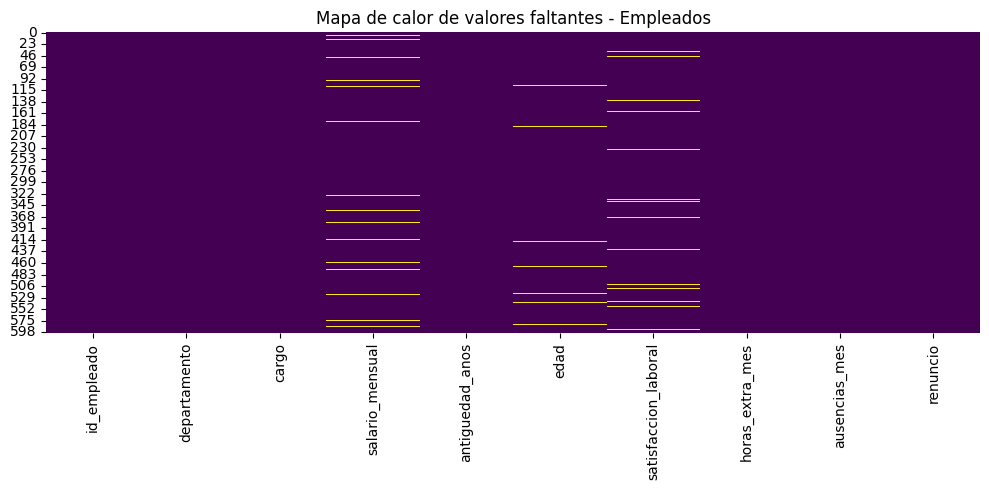

In [14]:
# Mapa de calor de valores faltantes en empleados
plt.figure(figsize=(10, 5))
sns.heatmap(df_empleados.isna(), cbar=False, cmap='viridis')
plt.title('Mapa de calor de valores faltantes - Empleados')
plt.tight_layout()
plt.show()

### Interpretación de los mapas de calor

Los mapas de calor permiten visualizar la ubicación de
los valores faltantes en ambos datasets y complementar
el diagnóstico realizado mediante las tablas de nulos.

En ventas, los valores faltantes se presentan en cinco
columnas, mientras que en empleados se concentran en
salario_mensual, edad y satisfaccion_laboral.

Esta visualización facilita la identificación de las
variables que requieren un tratamiento de imputación.

In [15]:
# Duplicados absolutos
print("Duplicados en ventas:", df_ventas.duplicated().sum())
print("Duplicados en empleados:", df_empleados.duplicated().sum())

Duplicados en ventas: 30
Duplicados en empleados: 0


In [16]:
# Duplicados por clave
print("ID de venta repetidos:",
      df_ventas.duplicated(subset=['id_venta']).sum())

print("ID de empleado repetidos:",
      df_empleados.duplicated(subset=['id_empleado']).sum())

ID de venta repetidos: 30
ID de empleado repetidos: 0


In [17]:
# Categorías de región
print(df_ventas['region'].value_counts(dropna=False))

region
Centro    191
SUR       185
Oeste     175
Norte     171
sur       170
Este      160
Sur       154
NORTE     153
norte     145
NaN        26
Name: count, dtype: int64


In [18]:
# Categorías de vendedor
print(df_ventas['vendedor'].value_counts(dropna=False))

vendedor
Diego Castro      176
Pedro Jiménez     175
Laura Torres      173
ana lópez         173
María González    167
CARLOS RUIZ       166
Carlos Ruiz       165
maria gonzalez    154
Ana López         140
NaN                41
Name: count, dtype: int64


In [19]:
# Categorías de empleados
print(df_empleados['departamento'].value_counts(dropna=False))
print(df_empleados['cargo'].value_counts(dropna=False))

departamento
Recursos Humanos    110
Sistemas            105
Finanzas            104
Marketing           104
Operaciones          92
Ventas               85
Name: count, dtype: int64
cargo
Analista        210
Especialista    198
Coordinador     118
Gerente          61
Director         13
Name: count, dtype: int64


In [20]:
# Anomalías numéricas en ventas
print("Precios negativos:",
      (df_ventas['precio_unitario'] < 0).sum())

print("Cantidades negativas:",
      (df_ventas['cantidad'] < 0).sum())

print("Cantidades iguales a cero:",
      (df_ventas['cantidad'] == 0).sum())

Precios negativos: 10
Cantidades negativas: 15
Cantidades iguales a cero: 0


In [21]:
# Revisión de fechas
fechas = pd.to_datetime(df_ventas['fecha_venta'], errors='coerce')

print("Fecha mínima:", fechas.min())
print("Fecha máxima:", fechas.max())
print("Fechas inválidas:", fechas.isna().sum())

Fecha mínima: 2023-01-01 00:00:00
Fecha máxima: 2023-12-31 00:00:00
Fechas inválidas: 0


### Interpretación de duplicados, inconsistencias y anomalías

En el dataset de ventas se identificaron 30 duplicados
absolutos y 30 identificadores repetidos. En el dataset
de empleados no se encontraron duplicados absolutos
ni identificadores repetidos.

Las columnas vendedor y region presentan inconsistencias
en el uso de mayúsculas, minúsculas y tildes, lo que puede
generar agrupaciones incorrectas durante el análisis.

Se identificaron 10 precios negativos y 15 cantidades
negativas, las cuales requieren un tratamiento antes
del análisis posterior.

Las fechas de venta se encuentran comprendidas entre
el 1 de enero y el 31 de diciembre de 2023, sin
registros de fechas inválidas.

## 3. Limpieza y normalización de texto

Se normalizarán las columnas vendedor y region para
unificar las categorías que presentan inconsistencias
en su escritura y evitar agrupaciones incorrectas
durante el análisis de datos.

In [22]:
# Normalización de texto
df_ventas['vendedor'] = df_ventas['vendedor'].str.strip().str.title()
df_ventas['region'] = df_ventas['region'].str.strip().str.title()

In [23]:
# Corrección de inconsistencias de tildes
df_ventas['vendedor'] = df_ventas['vendedor'].replace({
    'Maria Gonzalez': 'María González'
})

In [24]:
# Verificar las categorías normalizadas
print("Regiones:")
print(df_ventas['region'].value_counts(dropna=False))

print("\nVendedores:")
print(df_ventas['vendedor'].value_counts(dropna=False))

Regiones:
region
Sur       509
Norte     469
Centro    191
Oeste     175
Este      160
NaN        26
Name: count, dtype: int64

Vendedores:
vendedor
Carlos Ruiz       331
María González    321
Ana López         313
Diego Castro      176
Pedro Jiménez     175
Laura Torres      173
NaN                41
Name: count, dtype: int64


### Justificación de la normalización

Se utilizaron los métodos str.strip() y str.title()
para eliminar espacios innecesarios y estandarizar
el uso de mayúsculas y minúsculas.

Adicionalmente, se utilizó replace() para corregir
las inconsistencias de tildes en el nombre de una
vendedora.

Estas transformaciones permiten evitar que una misma
región o vendedor sea contabilizado como categorías
diferentes en los reportes comerciales.

Como resultado de la normalización, las categorías de
región se redujeron de nueve a cinco y las categorías
de vendedor de nueve a seis, sin eliminar registros.

## 4. Tratamiento de anomalías numéricas

Se identificarán y tratarán los precios negativos del
dataset de ventas antes de realizar la imputación de
valores faltantes.

In [25]:
# Visualizar ventas con precios negativos
df_ventas[df_ventas['precio_unitario'] < 0]

,id_venta,producto,cantidad,precio_unitario,fecha_venta,vendedor,region
137,138,PROD-0080,3.0,-68.271979,2023-03-09,Ana López,Oeste
290,291,PROD-0063,45.0,-93.165734,2023-09-06,Laura Torres,Norte
384,385,PROD-0053,8.0,-11.705716,2023-01-22,Carlos Ruiz,Sur
569,570,PROD-0042,39.0,-91.469122,2023-02-23,Diego Castro,Norte
686,687,PROD-0164,9.0,-22.440578,2023-09-20,Carlos Ruiz,Este
868,869,PROD-0168,44.0,-95.568591,2023-07-31,María González,Centro
1098,1099,PROD-0166,24.0,-34.601582,2023-12-25,Diego Castro,Centro
1199,1200,PROD-0020,34.0,-16.184569,2023-12-18,Diego Castro,Centro
1390,1391,PROD-0006,49.0,-58.168274,2023-01-09,María González,Oeste
1426,1427,PROD-0024,28.0,-45.264561,2023-11-08,Ana López,Este


In [26]:
# Convertir precios negativos en valores nulos
df_ventas.loc[df_ventas['precio_unitario'] < 0,
              'precio_unitario'] = np.nan

In [27]:
# Verificación del tratamiento de precios negativos
print("Precios negativos:",
      (df_ventas['precio_unitario'] < 0).sum())

print("Valores nulos en precio:",
      df_ventas['precio_unitario'].isna().sum())

Precios negativos: 0
Valores nulos en precio: 46


### Justificación del tratamiento de anomalías

Los precios negativos se consideraron valores inválidos
y se reemplazaron por NaN antes de realizar la imputación.

Se decidió no eliminar las filas completas, debido a que
contienen información relevante sobre el producto,
vendedor, región y fecha de venta.

Esta estrategia permite conservar la información válida
y evita que los precios negativos afecten los estadísticos
utilizados durante la imputación.

## 5. Identificación y eliminación de duplicados

Se eliminarán los registros duplicados para evitar
la contabilización repetida de ventas y garantizar
la integridad de los datos.

In [28]:
# Visualizar registros duplicados en ventas
df_ventas[df_ventas.duplicated(keep=False)].sort_values('id_venta')

,id_venta,producto,cantidad,precio_unitario,fecha_venta,vendedor,region
7,8,PROD-0131,16.0,99.52,2023-05-27,Carlos Ruiz,Sur
1505,8,PROD-0131,16.0,99.52,2023-05-27,Carlos Ruiz,Sur
1525,18,PROD-0054,13.0,1313.99,2023-11-27,Laura Torres,Sur
17,18,PROD-0054,13.0,1313.99,2023-11-27,Laura Torres,Sur
31,32,PROD-0091,28.0,967.24,2023-04-08,Pedro Jiménez,Norte
1500,32,PROD-0091,28.0,967.24,2023-04-08,Pedro Jiménez,Norte
1501,84,PROD-0055,16.0,1341.37,2023-12-13,Carlos Ruiz,Norte
83,84,PROD-0055,16.0,1341.37,2023-12-13,Carlos Ruiz,Norte
115,116,PROD-0186,30.0,NaN,2023-10-11,Laura Torres,Norte
1513,116,PROD-0186,30.0,NaN,2023-10-11,Laura Torres,Norte


In [29]:
# Eliminar duplicados absolutos
df_ventas = df_ventas.drop_duplicates(keep='first')
df_empleados = df_empleados.drop_duplicates(keep='first')

In [30]:
# Verificar dimensiones después de eliminar duplicados
print("Ventas:", df_ventas.shape)
print("Empleados:", df_empleados.shape)

# Verificar duplicados absolutos
print("Duplicados en ventas:", df_ventas.duplicated().sum())
print("Duplicados en empleados:", df_empleados.duplicated().sum())

# Verificar duplicados por clave
print("ID de venta repetidos:",
      df_ventas.duplicated(subset=['id_venta']).sum())

print("ID de empleado repetidos:",
      df_empleados.duplicated(subset=['id_empleado']).sum())

Ventas: (1500, 7)
Empleados: (600, 10)
Duplicados en ventas: 0
Duplicados en empleados: 0
ID de venta repetidos: 0
ID de empleado repetidos: 0


### Justificación de la eliminación de duplicados

Se identificaron y eliminaron 30 registros duplicados
en el dataset de ventas, conservando la primera
aparición de cada registro.

El dataset de ventas pasó de 1530 a 1500 registros,
mientras que el dataset de empleados mantuvo sus
600 registros.

Después de la eliminación, se verificó que no existieran
duplicados absolutos ni identificadores repetidos.

Este procedimiento se realizó antes de la imputación
para evitar que los registros duplicados influyeran
en los cálculos estadísticos.

## 6. Imputación de valores faltantes

Se aplicarán estrategias de imputación diferenciadas
según el tipo de variable y las características de
cada dataset, con el objetivo de conservar la mayor
cantidad de información posible.

In [31]:
# Valores faltantes antes de la imputación
print("Ventas:")
print(df_ventas.isna().sum())

print("\nEmpleados:")
print(df_empleados.isna().sum())

Ventas:
id_venta            0
producto           47
cantidad           29
precio_unitario    45
fecha_venta         0
vendedor           41
region             26
dtype: int64

Empleados:
id_empleado              0
departamento             0
cargo                    0
salario_mensual         28
antiguedad_anos          0
edad                    20
satisfaccion_laboral    32
horas_extra_mes          0
ausencias_mes            0
renuncio                 0
dtype: int64


In [32]:
# Calcular las medianas
mediana_cantidad = df_ventas['cantidad'].median()
mediana_precio = df_ventas['precio_unitario'].median()

print("Mediana de cantidad:", mediana_cantidad)
print("Mediana de precio:", mediana_precio)

Mediana de cantidad: 25.0
Mediana de precio: 787.17


In [33]:
# Imputación de variables numéricas
df_ventas['cantidad'] = df_ventas['cantidad'].fillna(mediana_cantidad)

df_ventas['precio_unitario'] = df_ventas['precio_unitario'].fillna(mediana_precio)

In [34]:
# Imputación de variables categóricas
df_ventas['producto'] = df_ventas['producto'].fillna('PROD-DESCONOCIDO')

df_ventas['vendedor'] = df_ventas['vendedor'].fillna('No reportado')

df_ventas['region'] = df_ventas['region'].fillna('Sin región')

In [35]:
# Verificar valores faltantes después de la imputación
print(df_ventas.isna().sum())

id_venta           0
producto           0
cantidad           0
precio_unitario    0
fecha_venta        0
vendedor           0
region             0
dtype: int64


### Justificación de la imputación en ventas

Para las variables numéricas cantidad y precio_unitario
se utilizó la mediana, debido a que es menos sensible
a los valores extremos que la media.

Para las variables categóricas se utilizaron valores
centinela: PROD-DESCONOCIDO, No reportado y Sin región.

Esta decisión permite conservar los registros sin
atribuir productos, vendedores o regiones incorrectas
a las ventas con información faltante.

Las cantidades negativas se conservaron debido a que
podrían representar devoluciones y no se dispone de
información suficiente para confirmar que sean errores.

### Imputación de variables numéricas en empleados

Se compararán los métodos de imputación mediante
la media y KNN para determinar cuál conserva mejor
las características estadísticas del dataset de
recursos humanos.

In [36]:
from sklearn.impute import SimpleImputer, KNNImputer

In [37]:
# Crear copias para comparar los métodos
df_media = df_empleados.copy()
df_knn = df_empleados.copy()

# Seleccionar las columnas con valores faltantes
cols_num = ['salario_mensual', 'edad', 'satisfaccion_laboral']

In [38]:
# Imputación mediante la media
imp_media = SimpleImputer(strategy='mean')

df_media[cols_num] = imp_media.fit_transform(df_media[cols_num])

In [39]:
from sklearn.preprocessing import StandardScaler

# Estandarización temporal para KNN
scaler_knn = StandardScaler()

datos_escalados = scaler_knn.fit_transform(df_knn[cols_num])

# Imputación mediante KNN
imp_knn = KNNImputer(n_neighbors=5, weights='distance')

datos_imputados = imp_knn.fit_transform(datos_escalados)

# Recuperar las unidades originales
df_knn[cols_num] = scaler_knn.inverse_transform(datos_imputados)

In [40]:
# Estadísticos antes de la imputación
desc_antes = df_empleados[cols_num].describe()

# Estadísticos después de imputar con media
desc_media = df_media[cols_num].describe()

# Estadísticos después de imputar con KNN
desc_knn = df_knn[cols_num].describe()

# Comparar los resultados
comparacion = pd.concat([
    desc_antes,
    desc_media,
    desc_knn
], keys=['Original', 'Media', 'KNN'], axis=1)

comparacion.round(2)

Original                                        Media          \
      salario_mensual    edad satisfaccion_laboral salario_mensual    edad   
count          572.00  580.00               568.00          600.00  600.00   
mean          2170.38   31.10                 5.26         2170.38   31.10   
std           1268.19    7.17                 2.09         1238.19    7.05   
min           1020.48   22.00                 1.00         1020.48   22.00   
25%           1354.32   26.00                 3.80         1381.06   26.00   
50%           1837.94   30.00                 5.30         1896.78   30.00   
75%           2458.68   34.00                 6.60         2409.89   34.00   
max           9521.86   65.00                10.00         9521.86   65.00   

                                       KNN                               
      satisfaccion_laboral salario_mensual    edad satisfaccion_laboral  
count               600.00          600.00  600.00               600.00  
mean                  5.26         2155.45   31.09                 5.28  
std                   2.03         1243.93    7.08                 2.05  
min                   1.00         1020.48   22.00                 1.00  
25%                   3.90         1366.70   26.00                 3.88  
50%                   5.28         1833.15   30.00                 5.40  
75%                   6.52         2426.43   34.00                 6.60  
max                  10.00         9521.86   65.00                10.00

In [41]:
# Verificación de ambos métodos
print("Nulos después de imputar con media:")
print(df_media[cols_num].isna().sum())

print("\nNulos después de imputar con KNN:")
print(df_knn[cols_num].isna().sum())

Nulos después de imputar con media:
salario_mensual         0
edad                    0
satisfaccion_laboral    0
dtype: int64

Nulos después de imputar con KNN:
salario_mensual         0
edad                    0
satisfaccion_laboral    0
dtype: int64


In [42]:
# Seleccionar KNN como método definitivo
df_empleados = df_knn.copy()

In [43]:
# Verificación final de valores faltantes
print("Nulos en ventas:", df_ventas.isna().sum().sum())
print("Nulos en empleados:", df_empleados.isna().sum().sum())

print("\nDimensiones finales:")
print("Ventas:", df_ventas.shape)
print("Empleados:", df_empleados.shape)

Nulos en ventas: 0
Nulos en empleados: 0

Dimensiones finales:
Ventas: (1500, 7)
Empleados: (600, 10)


### Justificación de la imputación en empleados

Se compararon los métodos de imputación mediante la
media y KNN, utilizando cinco vecinos y ponderación
por distancia.

Antes de aplicar KNN, se estandarizaron temporalmente
las variables numéricas para evitar que las diferencias
de escala influyeran excesivamente en el cálculo de
las distancias.

Ambos métodos permitieron completar los valores
faltantes. Sin embargo, KNN conservó mejor la
variabilidad original de las tres variables analizadas.

Por ejemplo, la desviación estándar del salario mensual
pasó de 1268.19 a 1238.19 mediante la media y a
1243.93 mediante KNN.

Asimismo, la mediana original del salario fue de
1837.94, mientras que con la media se obtuvo 1896.78
y con KNN se obtuvo 1833.15.

Por estas razones, se seleccionó KNN como método
definitivo de imputación para el dataset de empleados.

## 7. Escalado de variables numéricas

Se aplicarán los métodos MinMaxScaler, StandardScaler
y RobustScaler al dataset de empleados, con el propósito
de comparar sus efectos sobre la distribución de las
variables numéricas.

In [44]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

In [45]:
# Seleccionar variables para el escalado
cols_escalado = [
    'salario_mensual',
    'antiguedad_anos',
    'edad',
    'satisfaccion_laboral',
    'horas_extra_mes',
    'ausencias_mes'
]

In [46]:
# Crear copias para comparar los métodos
df_minmax = df_empleados.copy()
df_standard = df_empleados.copy()
df_robust = df_empleados.copy()

In [47]:
# Escalado MinMax
scaler_minmax = MinMaxScaler()

df_minmax[cols_escalado] = scaler_minmax.fit_transform(
    df_minmax[cols_escalado]
)

In [48]:
# Escalado estándar
scaler_standard = StandardScaler()

df_standard[cols_escalado] = scaler_standard.fit_transform(
    df_standard[cols_escalado]
)

In [49]:
# Escalado robusto
scaler_robust = RobustScaler()

df_robust[cols_escalado] = scaler_robust.fit_transform(
    df_robust[cols_escalado]
)

In [50]:
# Comparación de los métodos de escalado
comparacion_escalado = pd.concat([
    df_empleados[cols_escalado].describe(),
    df_minmax[cols_escalado].describe(),
    df_standard[cols_escalado].describe(),
    df_robust[cols_escalado].describe()
], keys=['Original', 'MinMax', 'Standard', 'Robust'], axis=1)

comparacion_escalado.round(2)

Original                                               \
      salario_mensual antiguedad_anos    edad satisfaccion_laboral   
count          600.00          600.00  600.00               600.00   
mean          2155.45            4.02   31.09                 5.28   
std           1243.93            4.19    7.08                 2.05   
min           1020.48            0.00   22.00                 1.00   
25%           1366.70            1.20   26.00                 3.88   
50%           1833.15            2.80   30.00                 5.40   
75%           2426.43            5.43   34.00                 6.60   
max           9521.86           25.00   65.00                10.00   

                                             MinMax                          \
      horas_extra_mes ausencias_mes salario_mensual antiguedad_anos    edad   
count          600.00        600.00          600.00          600.00  600.00   
mean             9.57          2.09            0.13            0.16    0.21   
std              6.75          1.45            0.15            0.17    0.16   
min              0.00          0.00            0.00            0.00    0.00   
25%              5.00          1.00            0.04            0.05    0.09   
50%              8.00          2.00            0.10            0.11    0.19   
75%             12.00          3.00            0.17            0.22    0.28   
max             43.00          7.00            1.00            1.00    1.00   

                            ... Standard                                       \
      satisfaccion_laboral  ...     edad satisfaccion_laboral horas_extra_mes   
count               600.00  ...   600.00               600.00          600.00   
mean                  0.48  ...     0.00                -0.00           -0.00   
std                   0.23  ...     1.00                 1.00            1.00   
min                   0.00  ...    -1.29                -2.09           -1.42   
25%                   0.32  ...    -0.72                -0.69           -0.68   
50%                   0.49  ...    -0.15                 0.06           -0.23   
75%                   0.62  ...     0.41                 0.64            0.36   
max                   1.00  ...     4.80                 2.30            4.96   

                             Robust                          \
      ausencias_mes salario_mensual antiguedad_anos    edad   
count        600.00          600.00          600.00  600.00   
mean           0.00            0.30            0.29    0.14   
std            1.00            1.17            0.99    0.88   
min           -1.44           -0.77           -0.66   -1.00   
25%           -0.75           -0.44           -0.38   -0.50   
50%           -0.06           -0.00            0.00    0.00   
75%            0.63            0.56            0.62    0.50   
max            3.40            7.26            5.25    4.38   

                                                          
      satisfaccion_laboral horas_extra_mes ausencias_mes  
count               600.00          600.00        600.00  
mean                 -0.04            0.22          0.04  
std                   0.75            0.96          0.72  
min                  -1.61           -1.14         -1.00  
25%                  -0.56           -0.43         -0.50  
50%                   0.00            0.00          0.00  
75%                   0.44            0.57          0.50  
max                   1.69            5.00          2.50  

[8 rows x 24 columns]

### Aplicación de los métodos de escalado

Se crearon tres copias independientes del dataset
de empleados para comparar los métodos de escalado
sin modificar los datos originales de trabajo.

Se excluyeron las columnas id_empleado y renuncio,
debido a que corresponden a un identificador y una
variable binaria, respectivamente.

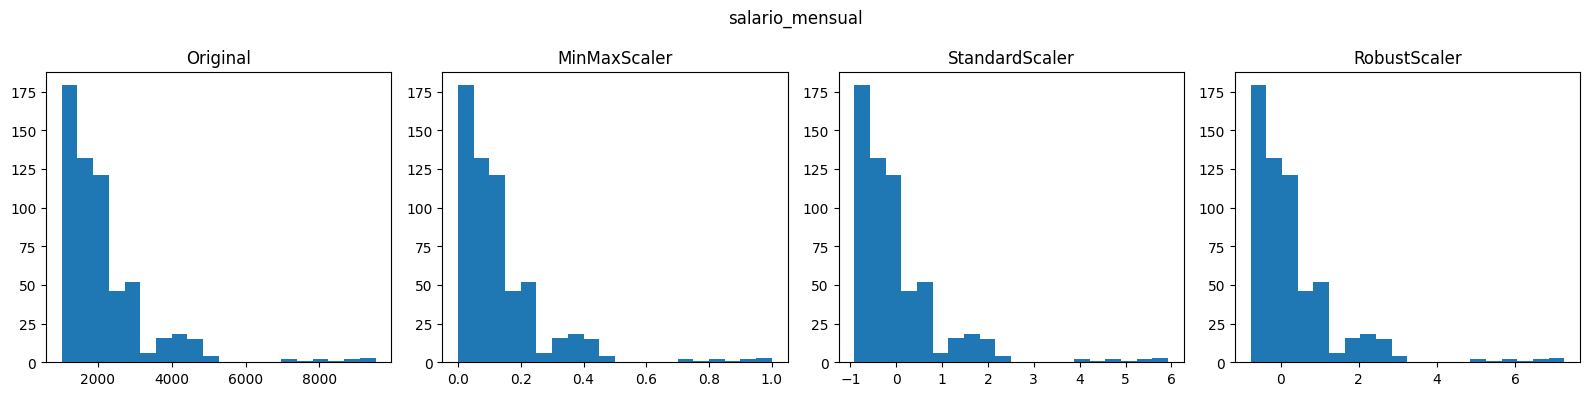

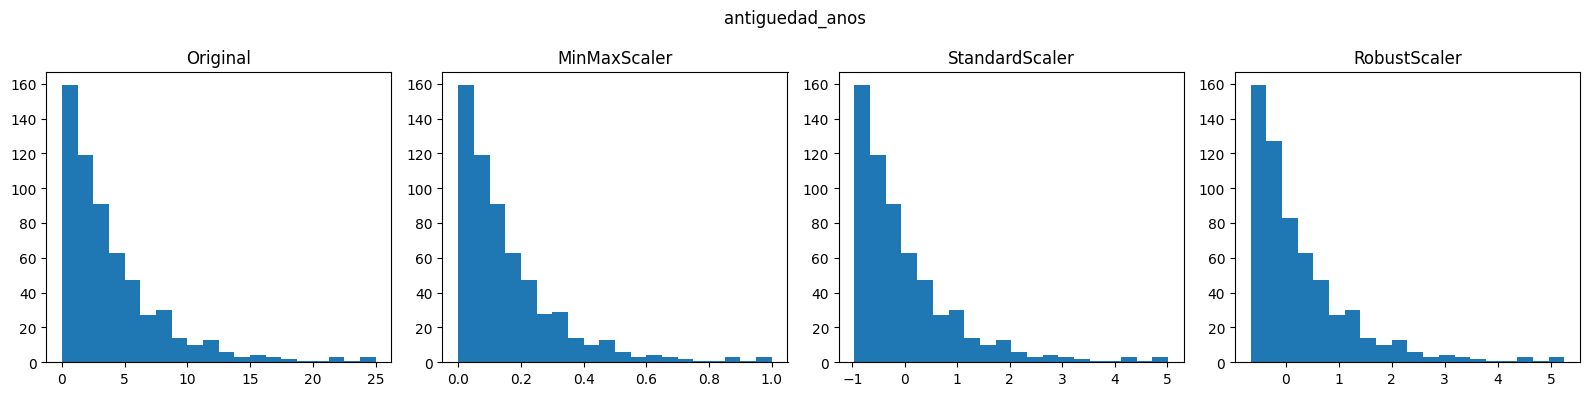

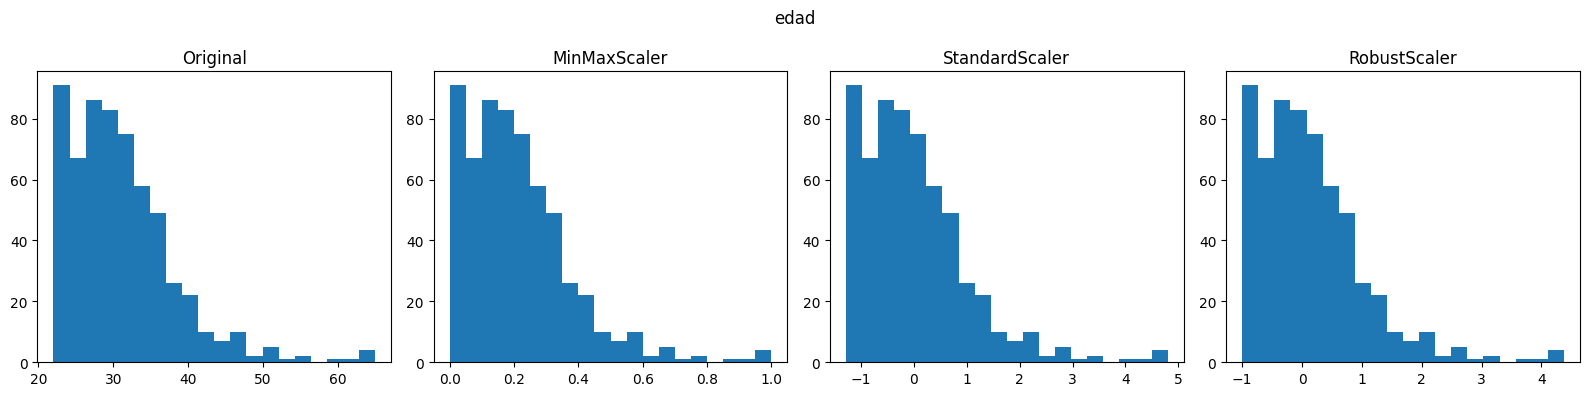

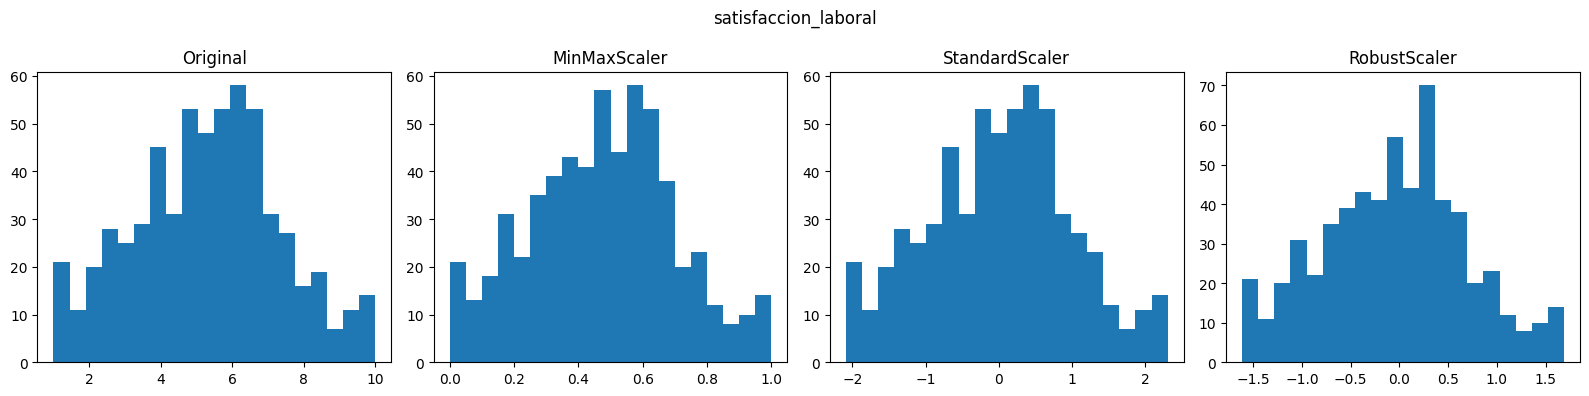

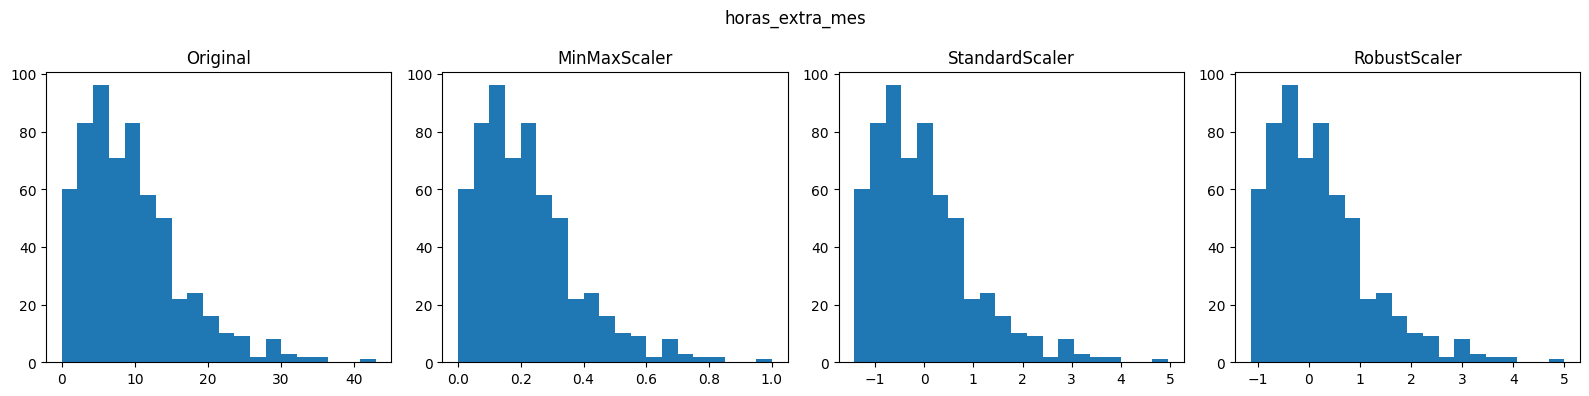

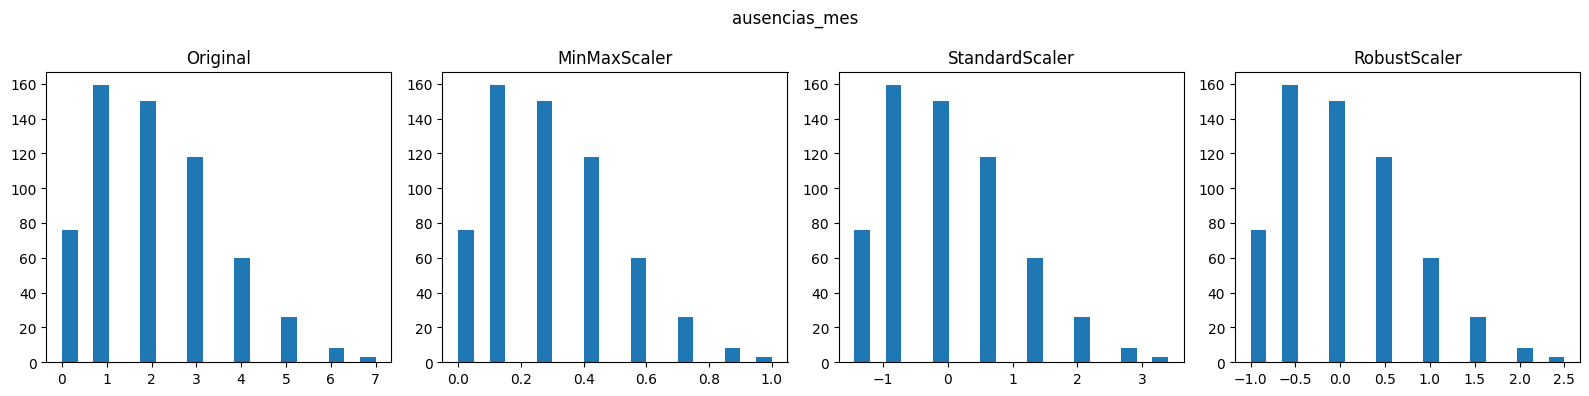

In [51]:
# Comparación visual de los métodos de escalado

for columna in cols_escalado:

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    axes[0].hist(df_empleados[columna], bins=20)
    axes[0].set_title('Original')

    axes[1].hist(df_minmax[columna], bins=20)
    axes[1].set_title('MinMaxScaler')

    axes[2].hist(df_standard[columna], bins=20)
    axes[2].set_title('StandardScaler')

    axes[3].hist(df_robust[columna], bins=20)
    axes[3].set_title('RobustScaler')

    fig.suptitle(columna)
    plt.tight_layout()
    plt.show()

In [52]:
# Identificación de valores atípicos mediante IQR

Q1 = df_empleados[cols_escalado].quantile(0.25)
Q3 = df_empleados[cols_escalado].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

atipicos = (
    (df_empleados[cols_escalado] < limite_inferior) |
    (df_empleados[cols_escalado] > limite_superior)
).sum()

print("Valores atípicos por variable:")
print(atipicos)

Valores atípicos por variable:
salario_mensual         48
antiguedad_anos         35
edad                    21
satisfaccion_laboral     0
horas_extra_mes         34
ausencias_mes            3
dtype: int64


### Comparación visual de los métodos de escalado

Se generaron histogramas comparativos para observar
el comportamiento de las seis variables numéricas
antes y después de aplicar los tres métodos de escalado.

Adicionalmente, se utilizó el rango intercuartílico
(IQR) para identificar posibles valores atípicos y
fundamentar la selección del método de escalado más
adecuado para cada variable.

El escalado modifica la magnitud de los datos sin
eliminar los valores atípicos ni alterar la forma
general de sus distribuciones.

### Selección de los métodos de escalado

Mediante el método IQR se identificaron 48 valores
atípicos en salario_mensual, 35 en antiguedad_anos,
21 en edad, 34 en horas_extra_mes y 3 en ausencias_mes.
La variable satisfaccion_laboral no presentó valores
atípicos.

Se recomienda RobustScaler para salario mensual,
antigüedad, edad y horas extra, debido a que utiliza
la mediana y el rango intercuartílico, siendo menos
sensible a los valores extremos.

Para satisfacción laboral se recomienda MinMaxScaler,
debido a que la variable posee una escala definida
entre 1 y 10 y no presenta valores atípicos.

Para ausencias mensuales se propone StandardScaler,
debido a la baja presencia de valores atípicos.

Se conservaron los datos en sus unidades originales
en el DataFrame principal para facilitar la creación
e interpretación de nuevas variables.

## 8. Feature Engineering

Se crearán nuevas variables a partir de las columnas
existentes en ambos datasets, con el objetivo de
enriquecer la información disponible y facilitar
el análisis comercial y de recursos humanos.

In [53]:
# Convertir fecha_venta a formato datetime
df_ventas['fecha_venta'] = pd.to_datetime(
    df_ventas['fecha_venta']
)

In [54]:
# Crear el total de cada venta
df_ventas = df_ventas.assign(
    total_venta = df_ventas['cantidad'] * df_ventas['precio_unitario']
)

In [55]:
# Crear variables temporales
df_ventas['mes_venta'] = df_ventas['fecha_venta'].dt.month

df_ventas['trimestre'] = df_ventas['fecha_venta'].dt.quarter

In [56]:
# Clasificar los movimientos según la cantidad
condiciones = [
    df_ventas['cantidad'] < 0,
    df_ventas['cantidad'] > 0
]

opciones = [
    'Posible devolución',
    'Venta'
]

df_ventas['tipo_movimiento'] = np.select(
    condiciones,
    opciones,
    default='Sin movimiento'
)

In [57]:
# Clasificación según la cantidad
df_ventas['nivel_cantidad'] = pd.cut(
    df_ventas['cantidad'],
    bins=[-np.inf, 0, 15, 30, np.inf],
    labels=['No positiva', 'Baja', 'Media', 'Alta']
)

In [58]:
# Segmentación de precios por cuartiles
df_ventas['segmento_precio'] = pd.qcut(
    df_ventas['precio_unitario'],
    q=4,
    labels=['Económico', 'Medio', 'Alto', 'Premium']
)

In [59]:
# Crear variable del día de la semana
dias = {
    0: 'Lunes',
    1: 'Martes',
    2: 'Miércoles',
    3: 'Jueves',
    4: 'Viernes',
    5: 'Sábado',
    6: 'Domingo'
}

df_ventas['dia_semana'] = df_ventas['fecha_venta'].apply(
    lambda fecha: dias[fecha.dayofweek]
)

In [60]:
# Visualizar las nuevas variables
display(df_ventas.head())

print("Dimensiones:", df_ventas.shape)
print("\nValores faltantes:")
print(df_ventas.isna().sum())

,id_venta,producto,cantidad,precio_unitario,fecha_venta,vendedor,region,total_venta,mes_venta,trimestre,tipo_movimiento,nivel_cantidad,segmento_precio,dia_semana
0,1,PROD-0076,41.0,248.47,2023-12-31,Diego Castro,Sur,10187.27,12,4,Venta,Alta,Económico,Domingo
1,2,PROD-0073,20.0,1102.81,2023-02-09,Carlos Ruiz,Sur,22056.20,2,1,Venta,Media,Alto,Jueves
2,3,PROD-0160,41.0,1091.88,2023-08-12,Ana López,Sur,44767.08,8,3,Venta,Alta,Alto,Sábado
3,4,PROD-0152,34.0,640.48,2023-06-01,Carlos Ruiz,Centro,21776.32,6,2,Venta,Alta,Medio,Jueves
4,5,PROD-0007,28.0,1387.55,2023-05-20,Carlos Ruiz,Sur,38851.40,5,2,Venta,Media,Premium,Sábado


Dimensiones: (1500, 14)

Valores faltantes:
id_venta           0
producto           0
cantidad           0
precio_unitario    0
fecha_venta        0
vendedor           0
region             0
total_venta        0
mes_venta          0
trimestre          0
tipo_movimiento    0
nivel_cantidad     0
segmento_precio    0
dia_semana         0
dtype: int64


### Justificación de las nuevas variables en ventas

Se crearon siete variables adicionales para enriquecer
el análisis comercial.

La variable total_venta permite calcular el importe
de cada movimiento, mientras que mes_venta, trimestre
y dia_semana facilitan el análisis temporal.

La variable tipo_movimiento permite identificar
cantidades negativas como posibles devoluciones,
sin eliminar información cuya naturaleza no ha sido
confirmada.

Mediante pd.cut() se clasificaron las cantidades en
intervalos definidos manualmente y mediante pd.qcut()
se segmentaron los precios en cuatro grupos basados
en cuartiles.

Estas transformaciones permiten realizar análisis
comerciales más detallados sin eliminar las variables
originales.

### Creación de nuevas variables en empleados

Se crearán variables adicionales para facilitar el
análisis salarial, demográfico y laboral de los
empleados de la empresa.

In [61]:
# Calcular salario anual
df_empleados = df_empleados.assign(
    salario_anual = df_empleados['salario_mensual'] * 12
)

In [62]:
# Clasificar satisfacción laboral
condiciones = [
    df_empleados['satisfaccion_laboral'] < 4,
    df_empleados['satisfaccion_laboral'] < 7
]

opciones = ['Baja', 'Media']

df_empleados['nivel_satisfaccion'] = np.select(
    condiciones,
    opciones,
    default='Alta'
)

In [63]:
# Clasificar empleados por grupos de edad
df_empleados['grupo_edad'] = pd.cut(
    df_empleados['edad'],
    bins=[0, 30, 45, 60, np.inf],
    labels=['Hasta 30', '31-45', '46-60', 'Mayor de 60']
)

In [64]:
# Clasificar salarios por cuartiles
df_empleados['segmento_salarial'] = pd.qcut(
    df_empleados['salario_mensual'],
    q=4,
    labels=['Bajo', 'Medio', 'Alto', 'Muy alto']
)

In [65]:
# Clasificar antigüedad laboral
def clasificar_antiguedad(anos):
    if anos < 2:
        return 'Reciente'
    elif anos < 5:
        return 'Intermedia'
    else:
        return 'Experimentado'

df_empleados['nivel_antiguedad'] = df_empleados[
    'antiguedad_anos'
].apply(clasificar_antiguedad)

In [66]:
# Clasificar carga laboral según horas extra
condiciones = [
    df_empleados['horas_extra_mes'] <= 5,
    df_empleados['horas_extra_mes'] <= 15
]

opciones = ['Baja', 'Media']

df_empleados['carga_laboral'] = np.select(
    condiciones,
    opciones,
    default='Alta'
)

In [67]:
# Codificación de departamentos
dummies_departamento = pd.get_dummies(
    df_empleados['departamento'],
    prefix='depto',
    dtype=int
)

df_empleados = pd.concat(
    [df_empleados, dummies_departamento],
    axis=1
)

In [68]:
# Verificar las nuevas variables
display(df_empleados.head())

print("Dimensiones:", df_empleados.shape)

print("\nValores faltantes:")
print(df_empleados.isna().sum())

,id_empleado,departamento,cargo,salario_mensual,antiguedad_anos,edad,satisfaccion_laboral,horas_extra_mes,ausencias_mes,renuncio,...,grupo_edad,segmento_salarial,nivel_antiguedad,carga_laboral,depto_Finanzas,depto_Marketing,depto_Operaciones,depto_Recursos Humanos,depto_Sistemas,depto_Ventas
0,1,Operaciones,Especialista,1591.98,2.9,25.0,4.7,4.0,2,0,...,Hasta 30,Medio,Intermedia,Baja,0,0,1,0,0,0
1,2,Marketing,Analista,1246.42,0.1,22.0,5.4,9.0,3,0,...,Hasta 30,Bajo,Reciente,Media,0,1,0,0,0,0
2,3,Marketing,Analista,1202.97,0.2,28.0,8.8,8.0,1,0,...,Hasta 30,Bajo,Reciente,Media,0,1,0,0,0,0
3,4,Recursos Humanos,Especialista,1665.51,1.9,31.0,8.3,7.0,3,0,...,31-45,Medio,Reciente,Media,0,0,0,1,0,0
4,5,Sistemas,Coordinador,2727.92,9.5,31.0,7.0,12.0,4,0,...,31-45,Muy alto,Experimentado,Media,0,0,0,0,1,0


Dimensiones: (600, 22)

Valores faltantes:
id_empleado               0
departamento              0
cargo                     0
salario_mensual           0
antiguedad_anos           0
edad                      0
satisfaccion_laboral      0
horas_extra_mes           0
ausencias_mes             0
renuncio                  0
salario_anual             0
nivel_satisfaccion        0
grupo_edad                0
segmento_salarial         0
nivel_antiguedad          0
carga_laboral             0
depto_Finanzas            0
depto_Marketing           0
depto_Operaciones         0
depto_Recursos Humanos    0
depto_Sistemas            0
depto_Ventas              0
dtype: int64


### Justificación de las nuevas variables en empleados

Se crearon doce columnas adicionales con el objetivo
de enriquecer el análisis de recursos humanos.

La variable salario_anual permite estimar el salario
base anual de cada empleado.

Las variables nivel_satisfaccion, grupo_edad,
segmento_salarial, nivel_antiguedad y carga_laboral
permiten segmentar a los empleados según diferentes
características demográficas y laborales.

Se utilizó pd.get_dummies() para transformar los
seis departamentos en variables binarias, facilitando
su utilización en futuros modelos de análisis de datos.

Los intervalos de clasificación fueron definidos
como criterios exploratorios para este laboratorio.

Finalmente, se verificó que las transformaciones
no generaran valores faltantes ni pérdida de registros.

In [69]:
# Resumen de las transformaciones
resumen_features = pd.DataFrame({
    'Dataset': ['Ventas', 'Empleados'],
    'Columnas originales': [
        ventas_original.shape[1],
        empleados_original.shape[1]
    ],
    'Columnas finales': [
        df_ventas.shape[1],
        df_empleados.shape[1]
    ]
})

resumen_features['Columnas nuevas'] = (
    resumen_features['Columnas finales'] -
    resumen_features['Columnas originales']
)

resumen_features

,Dataset,Columnas originales,Columnas finales,Columnas nuevas
0,Ventas,7,14,7
1,Empleados,10,22,12


## 9. Pipeline reproducible e idempotencia

Se desarrollará una función que permita automatizar
el proceso de limpieza de ambos datasets, garantizando
la reproducibilidad de las transformaciones.

Adicionalmente, se verificará la idempotencia del
proceso mediante la aplicación consecutiva de la
función sobre los datos.

In [70]:
def limpiar_dataset(path_in, path_out):
    """
    Limpia un dataset de ventas o empleados de Comercial
    del Pacífico S.A.

    Parámetros:
        path_in (str): Ruta del archivo CSV de entrada.
        path_out (str): Ruta del archivo CSV de salida.

    Transformaciones:
        - Normalización de texto.
        - Tratamiento de precios negativos.
        - Eliminación de duplicados.
        - Imputación de valores faltantes.

    Retorna:
        pd.DataFrame: Dataset limpio.

    Excepciones:
        ValueError: Si el tipo de dataset no es reconocido.
    """

    # Cargar el dataset
    df = pd.read_csv(path_in)

    # Limpieza del dataset de ventas
    if 'id_venta' in df.columns:

        # Normalización de texto
        df['vendedor'] = df['vendedor'].str.strip().str.title()
        df['region'] = df['region'].str.strip().str.title()

        # Corrección de inconsistencias
        df['vendedor'] = df['vendedor'].replace({
            'Maria Gonzalez': 'María González',
            'No Reportado': 'No reportado'
        })

        df['region'] = df['region'].replace({
            'Sin Región': 'Sin región'
        })

        # Tratamiento de precios negativos
        df.loc[df['precio_unitario'] < 0,
               'precio_unitario'] = np.nan

        # Eliminar duplicados
        df = df.drop_duplicates(keep='first').copy()

        # Imputación numérica mediante mediana
        df['cantidad'] = df['cantidad'].fillna(
            df['cantidad'].median()
        )

        df['precio_unitario'] = df['precio_unitario'].fillna(
            df['precio_unitario'].median()
        )

        # Imputación categórica
        df['producto'] = df['producto'].fillna(
            'PROD-DESCONOCIDO'
        )

        df['vendedor'] = df['vendedor'].fillna(
            'No reportado'
        )

        df['region'] = df['region'].fillna(
            'Sin región'
        )

    # Limpieza del dataset de empleados
    elif 'id_empleado' in df.columns:

        # Eliminar duplicados
        df = df.drop_duplicates(keep='first').copy()

        cols_num = [
            'salario_mensual',
            'edad',
            'satisfaccion_laboral'
        ]

        # Aplicar KNN solamente si existen valores faltantes
        if df[cols_num].isna().any().any():

            scaler = StandardScaler()

            datos_escalados = scaler.fit_transform(
                df[cols_num]
            )

            imputer = KNNImputer(
                n_neighbors=5,
                weights='distance'
            )

            datos_imputados = imputer.fit_transform(
                datos_escalados
            )

            df[cols_num] = scaler.inverse_transform(
                datos_imputados
            )

    else:
        raise ValueError("Dataset no reconocido")

    # Guardar el dataset limpio
    df.to_csv(path_out, index=False)

    return df

### Alcance de la función automatizada

La función `limpiar_dataset()` automatiza la limpieza
de los datasets de ventas y recursos humanos,
incluyendo la normalización de texto, el tratamiento
de valores inválidos, la eliminación de duplicados
y la imputación de valores faltantes.

El escalado y la ingeniería de características se
realizaron en secciones independientes del notebook,
ya que corresponden a etapas posteriores de
transformación de los datos.

Esta separación permite mantener un proceso de
limpieza reproducible y aplicar transformaciones
adicionales según los objetivos del análisis.

In [71]:
# Ejecutar el pipeline para ventas
ventas_pipeline = limpiar_dataset(
    'ventas_productos.csv',
    'ventas_pipeline.csv'
)

# Ejecutar el pipeline para empleados
empleados_pipeline = limpiar_dataset(
    'empleados_rrhh.csv',
    'empleados_pipeline.csv'
)

print("Ventas:", ventas_pipeline.shape)
print("Empleados:", empleados_pipeline.shape)

print("\nNulos en ventas:",
      ventas_pipeline.isna().sum().sum())

print("Nulos en empleados:",
      empleados_pipeline.isna().sum().sum())

Ventas: (1500, 7)
Empleados: (600, 10)

Nulos en ventas: 0
Nulos en empleados: 0


### Verificación de idempotencia

Se verificará que la función de limpieza pueda ejecutarse
sobre un dataset previamente limpiado sin modificar
nuevamente sus datos. Esto permite garantizar la
consistencia y reproducibilidad del proceso.

In [72]:
# Ejecutar nuevamente la limpieza sobre los archivos limpios
ventas_segunda = limpiar_dataset(
    'ventas_pipeline.csv',
    'ventas_segunda.csv'
)

empleados_segunda = limpiar_dataset(
    'empleados_pipeline.csv',
    'empleados_segunda.csv'
)

# Verificar idempotencia
pd.testing.assert_frame_equal(
    ventas_pipeline.reset_index(drop=True),
    ventas_segunda.reset_index(drop=True),
    check_dtype=False
)

pd.testing.assert_frame_equal(
    empleados_pipeline.reset_index(drop=True),
    empleados_segunda.reset_index(drop=True),
    check_dtype=False
)

print("Idempotencia en ventas: Correcta")
print("Idempotencia en empleados: Correcta")

Idempotencia en ventas: Correcta
Idempotencia en empleados: Correcta


### Comparación del pipeline con la limpieza manual

Se compararán los resultados obtenidos mediante la función
automatizada con los datasets limpiados manualmente, para
verificar la consistencia de las transformaciones aplicadas.

In [73]:
# Seleccionar las columnas originales
cols_ventas = ventas_original.columns
cols_empleados = empleados_original.columns

# Crear copias para la comparación
ventas_manual = df_ventas[cols_ventas].copy()
ventas_auto = ventas_pipeline[cols_ventas].copy()

# Unificar el formato de las fechas
ventas_manual['fecha_venta'] = pd.to_datetime(
    ventas_manual['fecha_venta']
)

ventas_auto['fecha_venta'] = pd.to_datetime(
    ventas_auto['fecha_venta']
)

# Comparar los resultados de ventas
pd.testing.assert_frame_equal(
    ventas_manual.reset_index(drop=True),
    ventas_auto.reset_index(drop=True),
    check_dtype=False
)

print("Comparación de ventas: Correcta")

# Comparar los resultados de empleados
pd.testing.assert_frame_equal(
    df_empleados[cols_empleados].reset_index(drop=True),
    empleados_pipeline[cols_empleados].reset_index(drop=True),
    check_dtype=False
)

print("Comparación de empleados: Correcta")

Comparación de ventas: Correcta
Comparación de empleados: Correcta


## 10. Exportación de los datasets limpios

Se exportarán los datasets finales en formato CSV,
incluyendo las transformaciones y las nuevas variables
generadas durante el proceso de limpieza.

In [74]:
# Exportar los datasets finales
df_ventas.to_csv('ventas_productos_limpio.csv', index=False)

df_empleados.to_csv('empleados_rrhh_limpio.csv', index=False)

print("Archivos exportados correctamente")

Archivos exportados correctamente


In [75]:
# Verificar los archivos exportados
ventas_final = pd.read_csv('ventas_productos_limpio.csv')
empleados_final = pd.read_csv('empleados_rrhh_limpio.csv')

print("Dimensiones de ventas:", ventas_final.shape)
print("Dimensiones de empleados:", empleados_final.shape)

print("Nulos en ventas:", ventas_final.isna().sum().sum())
print("Nulos en empleados:", empleados_final.isna().sum().sum())

Dimensiones de ventas: (1500, 14)
Dimensiones de empleados: (600, 22)
Nulos en ventas: 0
Nulos en empleados: 0


## 11. Conclusiones finales

El proceso de limpieza y transformación de datos permitió
mejorar la calidad de los datasets de ventas y recursos
humanos de Comercial del Pacífico S.A.

En el dataset de ventas se corrigieron inconsistencias
textuales, se trataron los precios negativos, se eliminaron
30 registros duplicados y se imputaron los valores faltantes
mediante la mediana y valores centinela.

En el dataset de empleados se compararon los métodos de
imputación mediante la media y KNN, seleccionando KNN por
conservar mejor la dispersión de las variables analizadas.

También se aplicaron tres métodos de escalado y se
identificaron valores atípicos mediante el rango
intercuartílico, lo que permitió justificar la selección
de los métodos de escalado según las características
de cada variable.

Se generaron siete nuevas variables en ventas y doce en
empleados, facilitando futuros análisis comerciales y
de recursos humanos.

Finalmente, se implementó una función automatizada de
limpieza, cuya idempotencia y consistencia con la limpieza
manual fueron verificadas.

Como resultado, se obtuvieron dos datasets sin valores
faltantes ni registros duplicados, preparados para
posteriores procesos de análisis de datos.